<a href="https://colab.research.google.com/github/ElSkart7/Animal-Classification/blob/Shahd-Preproccessing/notebooks/DATA_PREPROCCESSING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##1) Install & import





In [ ]:
!pip install -q datasets pillow pandas matplotlib scikit-learn


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.model_selection import train_test_split

from PIL import Image
from collections import Counter
import json
import os
import gc


## 2) Load the dataset

In [ ]:
dataset = load_dataset("Rapidata/Animals-10")
train_raw = dataset["train"]

print("Total images:", len(train_raw))

class_names = list(train_raw.features["label"].names)
print("Number of classes:", len(class_names))
print("Classes:", class_names)


Total images: 23554
Number of classes: 10
Classes: ['Butterfly', 'Cat', 'Chicken', 'Cow', 'Dog', 'Elephant', 'Horse', 'Sheep', 'Spider', 'Squirrel']


In [ ]:
label2id = {name: idx for idx, name in enumerate(class_names)}
id2label = {idx: name for name, idx in label2id.items()}

print("Label mapping:")
print(label2id)


Label mapping:
{'Butterfly': 0, 'Cat': 1, 'Chicken': 2, 'Cow': 3, 'Dog': 4, 'Elephant': 5, 'Horse': 6, 'Sheep': 7, 'Spider': 8, 'Squirrel': 9}


## 3) Settings of images

In [ ]:
IMG_SIZE = (128, 128)
RANDOM_STATE = 42
LIMIT = None


## 4) Read labels

In [ ]:
# Reading the label column directly
y = np.array(train_raw["label"], dtype=np.int64)
indices = np.arange(len(y))

if LIMIT is not None:
    indices = indices[:LIMIT]
    y = y[:LIMIT]

print("Working with", len(indices), "images")
print("Class counts:", dict(Counter(y.tolist())))


Working with 23554 images
Class counts: {0: 1603, 1: 1199, 2: 2993, 3: 1797, 4: 4811, 5: 1037, 6: 2598, 7: 1376, 8: 4340, 9: 1800}


## 5) Splitting

In [ ]:
# 70% train,30% temporary
idx_train, idx_temp = train_test_split(
    indices,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# split the 30%"15% validation & 15% test"
idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y[idx_temp]
)

# no overlap +full coverage
assert len(set(idx_train) & set(idx_val)) == 0
assert len(set(idx_train) & set(idx_test)) == 0
assert len(set(idx_val) & set(idx_test)) == 0
assert len(idx_train) + len(idx_val) + len(idx_test) == len(indices)

print("Train:", len(idx_train))
print("Validation:", len(idx_val))
print("Test:", len(idx_test))


Train: 16487
Validation: 3533
Test: 3534


In [ ]:

for name, idx in [("train", idx_train), ("validation", idx_val), ("test", idx_test)]:
    counts = Counter(y[idx].tolist())
    print(name, {id2label[k]: counts[k] for k in sorted(counts)})


train {'Butterfly': 1122, 'Cat': 839, 'Chicken': 2095, 'Cow': 1258, 'Dog': 3368, 'Elephant': 726, 'Horse': 1818, 'Sheep': 963, 'Spider': 3038, 'Squirrel': 1260}
validation {'Butterfly': 240, 'Cat': 180, 'Chicken': 449, 'Cow': 269, 'Dog': 721, 'Elephant': 156, 'Horse': 390, 'Sheep': 207, 'Spider': 651, 'Squirrel': 270}
test {'Butterfly': 241, 'Cat': 180, 'Chicken': 449, 'Cow': 270, 'Dog': 722, 'Elephant': 155, 'Horse': 390, 'Sheep': 206, 'Spider': 651, 'Squirrel': 270}


## 6) Preprocess and save each split


In [ ]:
os.makedirs("prepared_data", exist_ok=True)

def process_and_save(selected_indices, split_name):
    output_path = f"prepared_data/{split_name}.npy"

    # fixed-size array
    images = np.lib.format.open_memmap(
        output_path,
        mode="w+",
        dtype=np.uint8,
        shape=(len(selected_indices), IMG_SIZE[0], IMG_SIZE[1], 3)
    )

    labels = y[selected_indices]

    for position, original_index in enumerate(selected_indices):
        image = train_raw[int(original_index)]["image"]
        image = image.convert("RGB")
        image = image.resize(IMG_SIZE, Image.Resampling.LANCZOS)
        images[position] = np.asarray(image, dtype=np.uint8)

        if (position + 1) % 500 == 0:
            print(split_name, position + 1, "/", len(selected_indices))

    images.flush()
    np.save(f"prepared_data/{split_name}_labels.npy", labels)
    print("Saved:", split_name)
    del images
    gc.collect()

process_and_save(idx_train, "train")
process_and_save(idx_val, "validation")
process_and_save(idx_test, "test")

print("All datasets saved successfully!")


train 500 / 16487
train 1000 / 16487
train 1500 / 16487
train 2000 / 16487
train 2500 / 16487
train 3000 / 16487
train 3500 / 16487
train 4000 / 16487
train 4500 / 16487
train 5000 / 16487
train 5500 / 16487
train 6000 / 16487
train 6500 / 16487
train 7000 / 16487
train 7500 / 16487
train 8000 / 16487
train 8500 / 16487
train 9000 / 16487
train 9500 / 16487
train 10000 / 16487
train 10500 / 16487
train 11000 / 16487
train 11500 / 16487
train 12000 / 16487
train 12500 / 16487
train 13000 / 16487
train 13500 / 16487
train 14000 / 16487
train 14500 / 16487
train 15000 / 16487
train 15500 / 16487
train 16000 / 16487
Saved: train
validation 500 / 3533
validation 1000 / 3533
validation 1500 / 3533
validation 2000 / 3533
validation 2500 / 3533
validation 3000 / 3533
validation 3500 / 3533
Saved: validation
test 500 / 3534
test 1000 / 3534
test 1500 / 3534
test 2000 / 3534
test 2500 / 3534
test 3000 / 3534
test 3500 / 3534
Saved: test
All datasets saved successfully!


## 7) Batch generators


In [ ]:
try:
    from tensorflow.keras.utils import Sequence as _BaseSequence  # Keras-compatible when TF exists
except ImportError:
    _BaseSequence = object  # standalone fallback (numpy only)

class SplitGenerator(_BaseSequence):

    def __init__(self, images_path, labels_path, batch_size=32, shuffle=False):
        self.images = np.load(images_path, mmap_mode="r")  # uint8 view of the file
        self.labels = np.load(labels_path)                 # labels are small
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.order = np.arange(len(self.labels))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.labels) / self.batch_size))

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        batch_ids = self.order[start:start + self.batch_size]
        batch_x = np.asarray(self.images[batch_ids], dtype=np.float32) / 255.0
        batch_y = self.labels[batch_ids]
        return batch_x, batch_y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.default_rng(RANDOM_STATE).shuffle(self.order)


In [ ]:
BATCH_SIZE = 32

train_gen = SplitGenerator("prepared_data/train.npy", "prepared_data/train_labels.npy", BATCH_SIZE, shuffle=True)
val_gen = SplitGenerator("prepared_data/validation.npy", "prepared_data/validation_labels.npy", BATCH_SIZE)
test_gen = SplitGenerator("prepared_data/test.npy", "prepared_data/test_labels.npy", BATCH_SIZE)

print("Batches - train:", len(train_gen), "| validation:", len(val_gen), "| test:", len(test_gen))
print("Samples  - train:", len(train_gen.labels), "| validation:", len(val_gen.labels), "| test:", len(test_gen.labels))
print("Image shape per sample:", train_gen.images.shape[1:])


Batches - train: 516 | validation: 111 | test: 111
Samples  - train: 16487 | validation: 3533 | test: 3534
Image shape per sample: (128, 128, 3)


In [ ]:
# normalize in [0, 1]
X_batch, y_batch = train_gen[0]
print("One batch:", X_batch.shape, y_batch.shape, X_batch.dtype)
assert X_batch.min() >= 0 and X_batch.max() <= 1 and np.isfinite(X_batch).all()
print("Normalization check passed: batches come out in [0, 1]")


One batch: (32, 128, 128, 3) (32,) float32
Normalization check passed: batches come out in [0, 1]


## 8) showing Before & after

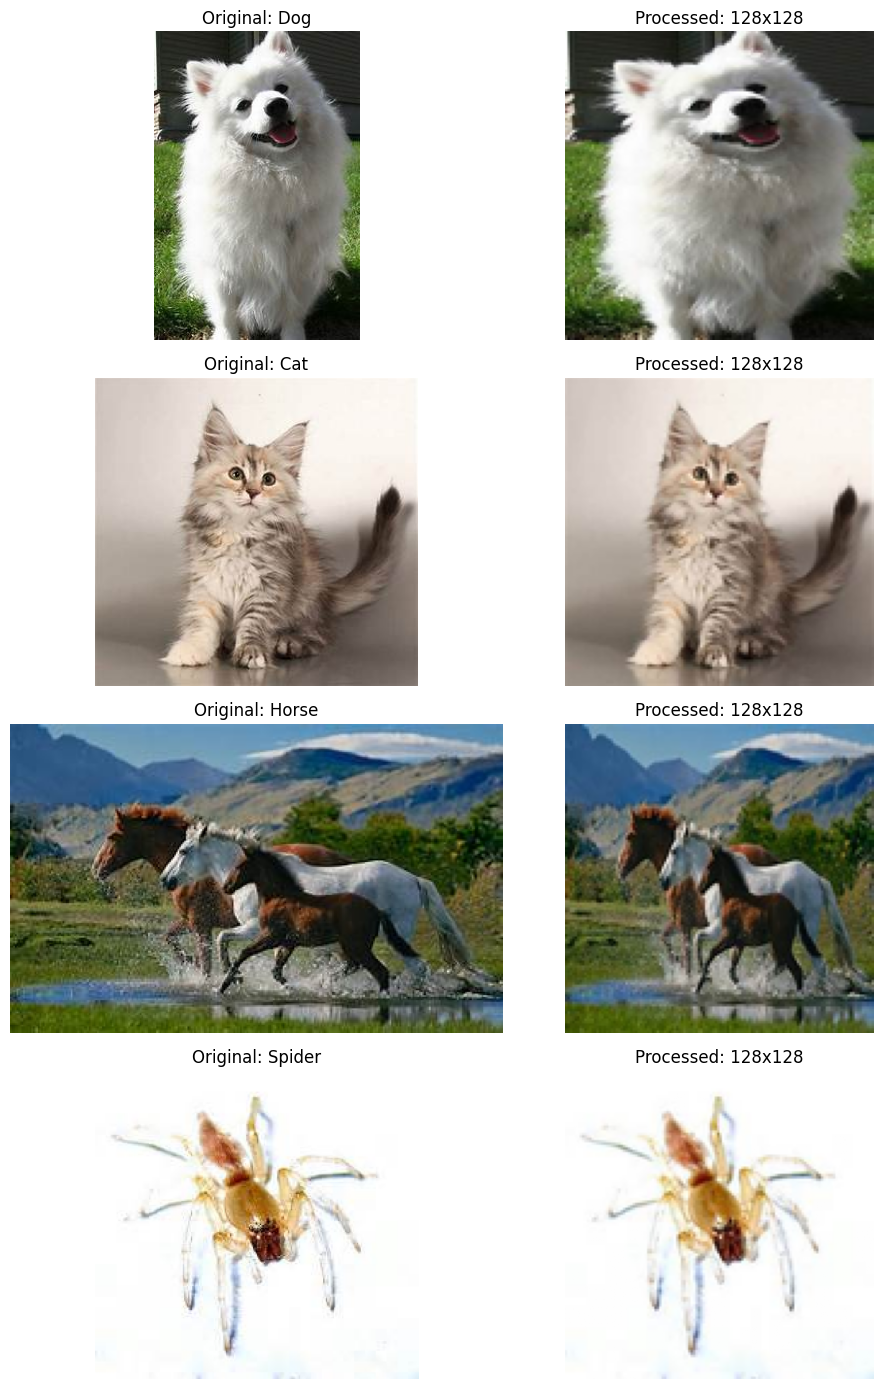

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
sample_indices = rng.choice(len(indices), size=4, replace=False)

fig, axes = plt.subplots(4, 2, figsize=(10, 14))

for row, idx in enumerate(sample_indices):
    global_idx = int(indices[idx])
    label_name = id2label[int(y[idx])]

    # original image
    original_img = train_raw[global_idx]["image"]
    axes[row, 0].imshow(original_img)
    axes[row, 0].set_title(f"Original: {label_name}")
    axes[row, 0].axis("off")

    # processed image
    processed = np.asarray(
        original_img.convert("RGB").resize(IMG_SIZE, Image.Resampling.LANCZOS),
        dtype=np.float32
    ) / 255.0
    axes[row, 1].imshow(processed)
    axes[row, 1].set_title(f"Processed: {IMG_SIZE[0]}x{IMG_SIZE[1]}")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


 ## **notes**

1. **Image Format & Size:**  All images are in RGB format with a fixed size of 128 × 128 pixels

2. **Dataset Splitting:** The dataset is divided into:
   - 70% Training Set
   - 15% Validation Set
   - 15% Test Set
 with random_state=42

3. **Label Mapping:** Each numerical label corresponds to a specific animal class. The mapping between label numbers and animal names is obtained from the label_mapping output.

4. **Data Type & Normalization:** The images are stored as uint8. The data generators automatically convert them to float32 and scale pixel values to the range [0, 1]. Therefore, no additional normalization is required.

